In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as sps
from tqdm import tqdm

# Задача 1. Формула MDE для среднего при известной дисперсии

Рассмотрим одновыборочный $Z$-тест для среднего нормального распределения при известной дисперсии $\sigma^2$. Размер выборки равен $n$, уровень значимости теста равен $\alpha$, а требуемая мощность равна $1-\beta$.

Тестовая статистика:

$$
Z=\frac{\overline X-\mu_0}{\sigma/\sqrt n}.
$$

Требуется:

1. вывести формулу $MDE$ для правосторонней альтернативы $H_1:\mu>\mu_0$;
2. вывести формулу $MDE$ для левосторонней альтернативы $H_1:\mu<\mu_0$;
3. вывести формулу $MDE$ для двусторонней альтернативы $H_1:\mu\ne\mu_0$;
4. сравнить полученные формулы;
5. выразить необходимый размер выборки $n$ через фиксированный $MDE$;
6. вычислить $MDE$ и необходимый размер выборки при заданных параметрах.


**Решение**

## Пункт 1. Правосторонний тест

Для правостороннего теста

$$
H_0:\mu=\mu_0
\quad\text{против}\quad
H_1:\mu>\mu_0
$$

критическая область имеет вид

$$
Z>z_{1-\alpha}.
$$

Пусть

$$
\mu=\mu_0+\Delta,
\qquad \Delta>0.
$$

Тогда

$$
Z\sim N\left(\frac{\Delta\sqrt n}{\sigma},1\right).
$$

Мощность:

$$
1-\beta
=
\mathbb P_{\mu_0+\Delta}(Z>z_{1-\alpha})
=
1-\Phi\left(
z_{1-\alpha}-\frac{\Delta\sqrt n}{\sigma}
\right).
$$

Следовательно,

$$
\Phi\left(
z_{1-\alpha}-\frac{\Delta\sqrt n}{\sigma}
\right)=\beta.
$$

Так как $z_\beta=-z_{1-\beta}$, то

$$
z_{1-\alpha}-\frac{\Delta\sqrt n}{\sigma}
=
-z_{1-\beta}.
$$

Отсюда

$$
\operatorname{MDE}_{\text{right}}
=
\left(z_{1-\alpha}+z_{1-\beta}\right)
\frac{\sigma}{\sqrt n}.
$$


## Пункт 2. Левосторонний тест

Для левостороннего теста

$$
H_0:\mu=\mu_0
\quad\text{против}\quad
H_1:\mu<\mu_0
$$

критическая область имеет вид

$$
Z<z_\alpha=-z_{1-\alpha}.
$$

Пусть

$$
\mu=\mu_0-\Delta,
\qquad \Delta>0.
$$

Тогда

$$
Z\sim N\left(-\frac{\Delta\sqrt n}{\sigma},1\right).
$$

Мощность:

$$
1-\beta
=
\mathbb P_{\mu_0-\Delta}(Z<z_\alpha)
=
\Phi\left(
z_\alpha+\frac{\Delta\sqrt n}{\sigma}
\right).
$$

Значит,

$$
z_\alpha+\frac{\Delta\sqrt n}{\sigma}
=
z_{1-\beta}.
$$

Так как $z_\alpha=-z_{1-\alpha}$, получаем

$$
\operatorname{MDE}_{\text{left}}=
\left(z_{1-\alpha}+z_{1-\beta}\right)
\frac{\sigma}{\sqrt n}.
$$

Правосторонний и левосторонний тесты имеют одинаковый $MDE$ по модулю. Отличается только направление обнаруживаемого сдвига.


## Пункт 3. Двусторонний тест

Для двустороннего теста

$$
H_0:\mu=\mu_0
\quad\text{против}\quad
H_1:\mu\ne\mu_0
$$

критическая область имеет вид

$$
|Z|>z_{1-\alpha/2}.
$$

Пусть

$$
\mu=\mu_0+\Delta,
\qquad \Delta>0.
$$

Точная мощность равна

$$
1-\beta
=
1-\Phi\left(
z_{1-\alpha/2}
-
\frac{\Delta\sqrt n}{\sigma}
\right)
+
\Phi\left(
-z_{1-\alpha/2}
-
\frac{\Delta\sqrt n}{\sigma}
\right).
$$

Поэтому точный двусторонний $MDE$ определяется как положительное решение уравнения

$$
1-\Phi\left(
z_{1-\alpha/2}
-
\frac{\operatorname{MDE}_{\text{двуст}}\sqrt n}{\sigma}
\right)
+
\Phi\left(
-z_{1-\alpha/2}
-
\frac{\operatorname{MDE}_{\text{двуст}}\sqrt n}{\sigma}
\right)
=
1-\beta.
$$

Это уравнение обычно решается численно.

Если вероятность отклонения через хвост, противоположный направлению эффекта, пренебрежимо мала, получаем стандартную приближённую формулу

$$
\operatorname{MDE}_{\text{two}}
\approx
\left(z_{1-\alpha/2}+z_{1-\beta}\right)
\frac{\sigma}{\sqrt n}.
$$


## Пункт 4. Сравнение одностороннего и двустороннего тестов

Для одностороннего теста весь уровень значимости $\alpha$ находится в одном хвосте, поэтому используется квантиль

$$
z_{1-\alpha}.
$$

Для двустороннего теста уровень значимости делится между двумя хвостами, поэтому используется более высокий квантиль

$$
z_{1-\alpha/2}.
$$

Так как

$$
z_{1-\alpha/2}>z_{1-\alpha},
$$

то

$$
\operatorname{MDE}_{\text{two}}
>
\operatorname{MDE}_{\text{one}}.
$$

Итог:

$$
\operatorname{MDE}_{\text{right}}
=
\operatorname{MDE}_{\text{left}}
=
\left(z_{1-\alpha}+z_{1-\beta}\right)
\frac{\sigma}{\sqrt n}.
$$

и

$$
\operatorname{MDE}_{\text{two}}
\approx
\left(z_{1-\alpha/2}+z_{1-\beta}\right)
\frac{\sigma}{\sqrt n}.
$$


## Пункт 5. От формулы MDE к формуле $n$

Пусть фиксированный минимальный обнаруживаемый эффект равен

$$
\operatorname{MDE}=\Delta.
$$

Для одностороннего теста

$$
\Delta
=
\left(z_{1-\alpha}+z_{1-\beta}\right)
\frac{\sigma}{\sqrt n}.
$$

Отсюда

$$
n=\frac{\left(z_{1-\alpha}+z_{1-\beta}\right)\sigma}{\Delta}^2.
$$

Так как $n$ должно быть целым,

$$
n_{\text{one}}=(\frac{(z_{1-\alpha}+z_{1-\beta})\sigma}{\Delta})^2.
$$

Для двустороннего теста

$$
n_{\text{two}}=(\frac{(z_{1-\frac{\alpha}{2}}+z_{1-\beta})\sigma}{\Delta})^2.
$$


При фиксированном $MDE$ двусторонний тест требует большего числа наблюдений.


## Пункт 6. Пример расчёта

Пусть

$$
\alpha=0.05,
\qquad
1-\beta=0.8,
\qquad
\sigma=6,
\qquad
n=50.
$$

Также найдём необходимый размер выборки при фиксированном эффекте

$$
\Delta=2.
$$


In [ ]:
from scipy.stats import norm
import math

alpha = 0.05
power = 0.8
sigma = 6
n = 50
fixed_mde = 2

mde_one_sided = (norm.ppf(1 - alpha) + norm.ppf(power)) * sigma / math.sqrt(n)
mde_two_sided = (norm.ppf(1 - alpha / 2) + norm.ppf(power)) * sigma / math.sqrt(n)

n_one_sided = math.ceil(((norm.ppf(1 - alpha) + norm.ppf(power)) * sigma / fixed_mde) ** 2)
n_two_sided = math.ceil(((norm.ppf(1 - alpha / 2) + norm.ppf(power)) * sigma / fixed_mde) ** 2)

print("Правосторонний MDE:", round(mde_one_sided, 4))
print("Левосторонний MDE:", round(mde_one_sided, 4))
print("Двусторонний MDE:", round(mde_two_sided, 4))
print()
print("Необходимое n для одностороннего теста для MDE=2:", n_one_sided)
print("Необходимое n для двустороннего теста для MDE=2:", n_two_sided)

Правосторонний MDE: 2.1098
Левосторонний MDE: 2.1098
Двусторонний MDE: 2.3772

Необходимое n для одностороннего теста для MDE=2: 56
Необходимое n для двустороннего теста для MDE=2: 71


# Задача 2. Зависимость мощности и MDE от параметров эксперимента


Во всех пунктах можно использовать метод Монте-Карло, генерируя данные из нормального распределения.

В каждом отдельном тесте выбирай уровень значимости равным $5\%$, а минимальную мощность детектирования — $80\%$.


In [ ]:
def ztest_1sample(pop_mean, sample_mean, sample_std, sample_size, alternative='two-sided'):
    statistic = (sample_mean - pop_mean)/(sample_std / sample_size**0.5)
    if alternative == 'less':
        pvalue = sps.norm.cdf(statistic)
    if alternative == 'greater':
        pvalue = 1 - sps.norm.cdf(statistic)
    if alternative == 'two-sided':
        pvalue = 2 * (1 - sps.norm.cdf(abs(statistic)))
    return statistic, pvalue

def ztest_1sample_data(pop_mean, sample, alternative='two-sided'):
    return ztest_1sample(pop_mean, sample_mean=sample.mean(),
                         sample_std=sample.std(), sample_size=len(sample),
                         alternative=alternative)

In [ ]:
def ztest_2sample(sample1_mean, sample2_mean, sample1_std, sample2_std, sample1_size, sample2_size, alternative='two-sided'):
    statistic = (sample1_mean - sample2_mean) / (sample1_std ** 2 / sample1_size + sample2_std ** 2 / sample2_size) ** 0.5
    if alternative == 'less':
        pvalue = sps.norm.cdf(statistic)
    if alternative == 'greater':
        pvalue = 1 - sps.norm.cdf(statistic)
    if alternative == 'two-sided':
        pvalue = 2 * (1 - sps.norm.cdf(abs(statistic)))
    return statistic, pvalue

def ztest_2sample_data(sample1, sample2, alternative='two-sided'):
    return ztest_2sample(
        sample1_mean=sample1.mean(), sample2_mean=sample2.mean(),
        sample1_std=sample1.std(), sample2_std=sample2.std(),
        sample1_size=len(sample1), sample2_size=len(sample2),
        alternative=alternative
    )

## Пункт 1. Расчёт мощности теста при фиксированных параметрах одновыборочного критерия

Найди мощность z-теста $H_0:\mu = 100$, $H_1: \mu > 100$.

Случайная выборка размера $100$ наблюдений из распределения $\mathcal{N}(\mu,\sigma^2)$.

Найди мощность z-теста при $\mu=120$, $\sigma=40$ и проинтерпретируй найденное число.

**Решение**

Мощность теста $P_{H_1\text{ верна}}(\text{отклонить }H_0)$ — вероятность правильно отвергнуть $H_0$ при истинной $H_1$ (вероятность не совершить ошибку второго рода). Определим мощность теста методом Монте-Карло.

In [ ]:
rejections = 0
n_monte_carlo = 10000
mu0 = 100 # проверяемое значение из гипотезы
mu = 120  # истинное значение среднего
sigma = 40
sample_size = 100

for _ in range(n_monte_carlo):
    sample = sps.norm.rvs(loc=mu, scale=sigma, size=sample_size)
    test_stat, pvalue = ztest_1sample(pop_mean=mu0, sample_mean=sample.mean(), sample_std=sample.std(), sample_size=sample_size, alternative='greater')
    if pvalue < 0.05:
        rejections += 1

print(str(rejections / 10000 * 100) + '%')

99.94%


Мощность около $100\%$ означает, что данный тест при заданном уровне значимости $5\%$ точно обнаружит эффект, если он действительно существует.

## Пункт 2. Расчёт мощности теста при различных параметрах одновыборочного критерия

Построй график мощности z-теста $H_0:\mu = 100$, $H_1: \mu > 100$.

Cлучайная выборка размера n наблюдений из распределения $\mathcal{N}(\mu,\sigma^2)$.

Построй график мощности z-теста при разных эффектах на среднее, разных размерах выборки n и разных $\sigma$.


**Решение**

Воспользуемся функцией для нахождения мощности методом Монте-Карло и выберем сетку значений $\sigma$ и $n$ для изображения графиков мощности теста.

In [ ]:
def zpower_1sample_monte_carlo(mu0, mu, sigma, sample_size, n_monte_carlo, significance_level=0.05):
    rejections = 0

    for _ in range(n_monte_carlo):
        sample = sps.norm.rvs(loc=mu, scale=sigma, size=sample_size)
        test_stat, pvalue = ztest_1sample(pop_mean=mu0, sample_mean=sample.mean(), sample_std=sample.std(), sample_size=sample_size, alternative='two-sided')
        if pvalue < significance_level:
            rejections += 1

    return rejections / n_monte_carlo

In [ ]:
sigmas = [20, 40, 60]
sizes = [50, 200, 500]
n_monte_carlo = 1000
powers, means = [], []

for effect in np.arange(1, 40, 1):
    means.append(mu0 + effect)

for size in tqdm(sizes):
    for sigma in sigmas:
        effect_powers = []
        for effect in np.arange(1, 40, 1):
            effect_powers.append(zpower_1sample_monte_carlo(mu0=mu0, mu=mu0 + effect, sigma=sigma, sample_size=size, n_monte_carlo=n_monte_carlo))
        powers.append(effect_powers)

100%|██████████| 3/3 [01:30<00:00, 30.20s/it]


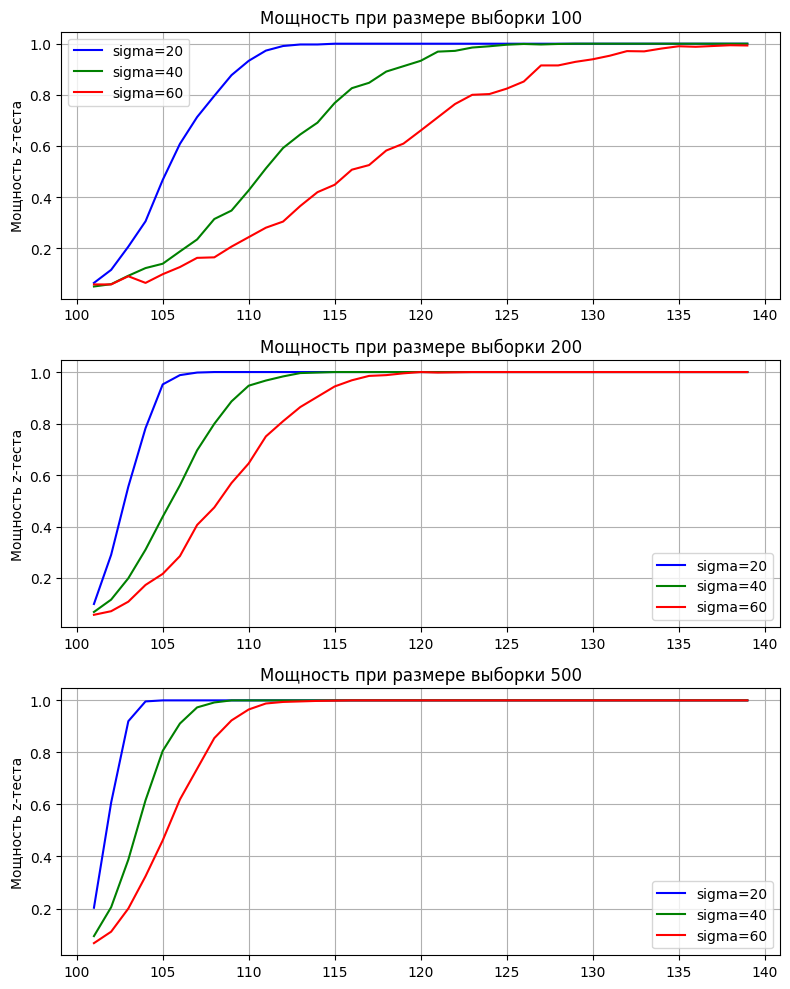

In [ ]:
plt.figure(figsize=(8, 10))

# Первый подграфик для размера выборки 100
plt.subplot(3, 1, 1)
plt.plot(means, powers[0], color='blue', label='sigma=20')
plt.plot(means, powers[1], color='green', label='sigma=40')
plt.plot(means, powers[2], color='red', label='sigma=60')
plt.title('Мощность при размере выборки 100')
plt.ylabel('Мощность z-теста')
plt.legend()
plt.grid()

# Второй подграфик для размера выборки 200
plt.subplot(3, 1, 2)
plt.plot(means, powers[3], color='blue', label='sigma=20')
plt.plot(means, powers[4], color='green', label='sigma=40')
plt.plot(means, powers[5], color='red', label='sigma=60')
plt.title('Мощность при размере выборки 200')
plt.ylabel('Мощность z-теста')
plt.legend()
plt.grid()

# Третий подграфик для размера выборки 500
plt.subplot(3, 1, 3)
plt.plot(means, powers[6], color='blue', label='sigma=20')
plt.plot(means, powers[7], color='green', label='sigma=40')
plt.plot(means, powers[8], color='red', label='sigma=60')
plt.title('Мощность при размере выборки 500')
plt.ylabel('Мощность z-теста')
plt.legend()
plt.grid()

# Отображение графиков
plt.tight_layout()  # Корректирует макет, чтобы предотвратить наложение
plt.show()

Ожидаемо, мощность теста увеличивается с увеличением размера выборки, при этом для каждого размера тест с меньшим разбросом $\sigma$ имеет большую мощность, чем тест с большим.

## Пункт 3. Расчёт MDE при различных параметрах одновыборочного критерия

Найди минимально детектируемый эффект при разных параметрах выборки из прошлого пункта.

**Решение**

In [ ]:
for idx_group, power_group in enumerate(powers):
    for idx, power in enumerate(power_group):
        if power >= 0.8:
            print(
                'Минимально детектируемый эффект для выборки размера', sizes[idx_group // 3],
                'с sigma =', sigmas[idx_group % 3], ':', means[idx] - 100
            )
            break

Минимально детектируемый эффект для выборки размера 50 с sigma = 20 : 9
Минимально детектируемый эффект для выборки размера 50 с sigma = 40 : 16
Минимально детектируемый эффект для выборки размера 50 с sigma = 60 : 23
Минимально детектируемый эффект для выборки размера 200 с sigma = 20 : 5
Минимально детектируемый эффект для выборки размера 200 с sigma = 40 : 9
Минимально детектируемый эффект для выборки размера 200 с sigma = 60 : 12
Минимально детектируемый эффект для выборки размера 500 с sigma = 20 : 3
Минимально детектируемый эффект для выборки размера 500 с sigma = 40 : 5
Минимально детектируемый эффект для выборки размера 500 с sigma = 60 : 8


Аналогично выводам этой задачи минимально детектируемый эффект для выборки с большим размером (при равных $sigma$) меньше, чем для выборок с маленьким размером. При этом минимально детектируемый эффект для выборок с большим разбросом $\sigma$ больше, чем для выборок с маленьким разбросом.

## Пункт 4. Расчёт мощности при различных параметрах двухвыборочного эксперимента

Построй график мощности z-теста $H_0:\mu_1 = \mu_2$, $H_1: \mu_1 > \mu_2$.

Независимые случайные выборки размера 100 и 200 наблюдений из распределений $\mathcal{N}(\mu_1, \sigma_2^2)$ и $\mathcal{N}(\mu_2, \sigma_2^2)$, при $\sigma_1 = 120$, $\sigma_2 = 80$.

Построй график мощности z-теста в зависимости от эффекта $\mu_1-\mu_2$.

Найди минимально детектируемый эффект на разность $\mu_1 - \mu_2$.

**Решение**

In [ ]:
def zpower_2sample_monte_carlo(mu1, mu2, sigma1, sigma2, sample1_size, sample2_size, n_monte_carlo, importance_level=0.05):
    rejections = 0

    for _ in range(n_monte_carlo):
        sample1 = sps.norm.rvs(loc=mu1, scale=sigma1, size=sample1_size)
        sample2 = sps.norm.rvs(loc=mu2, scale=sigma2, size=sample2_size)
        test_stat, pvalue = ztest_2sample(
            sample1.mean(), sample2.mean(),
            sample1.std(), sample2.std(),
            sample1_size, sample2_size, alternative='greater'
        )
        if pvalue < importance_level:
            rejections += 1

    return rejections / n_monte_carlo

Зафиксируем среднее значение выборки = 100 и заполним вектор мощностей для каждого эффекта на данное среднее.

In [ ]:
mean = 100
effects = np.arange(0, 200, 1)
powers = []

for effect in effects:
    powers.append(
        zpower_2sample_monte_carlo(
          mu1=mean, mu2=mean - effect, sigma1=120, sigma2=80,
          sample1_size=100, sample2_size=200, n_monte_carlo=1000
        )
    )

In [ ]:
for idx, power in enumerate(powers):
    if power >= 0.8:
        print('Минимально детектируемый эффект:', effects[idx])
        break

Минимально детектируемый эффект: 33


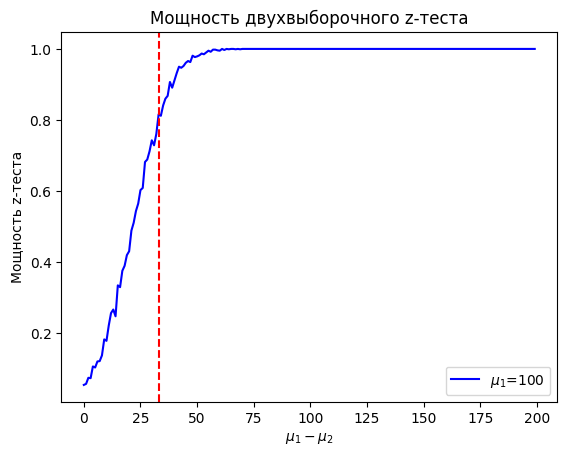

In [ ]:
plt.plot(effects, powers, color='blue', label=r'$\mu_1$=100')
plt.axvline(x=effects[idx], linestyle='dashed', color='red')

plt.xlabel(r'$\mu_1 - \mu_2$')
plt.ylabel("Мощность z-теста")
plt.title("Мощность двухвыборочного z-теста")
plt.legend()

plt.show()

Полученный минимально детектируемый эффект означает, что в данном тесте различие между средними будет обнаружено с $80\%$ вероятностью, если оно будет $\geq 34$. Меньшие различия будут детектироваться тестом с вероятностью $<80\%$.

## Пункт 5. Зависимость MDE от параметров двухвыбоочного критерия

Как изменится минимально необходимый размер выборки, если увеличить обнаруживаемый эффект
с $\mu_1 - \mu_2 = +30$ до $\mu_1 - \mu_2 = +60$ для двухвыборочного z-теста с гипотезой $H_0:\mu_1 = \mu_1$, $H_1: \mu_1 \ne \mu_2$ и независимых случайных выборок из распределений $\mathcal{N}(\mu_1,\sigma_1^2)$ и $\mathcal{N}(\mu_2,\sigma_2^2)$ при $\sigma_1 = 120$, $\sigma_2 = 80$.

**Решение**

In [ ]:
mean = 300

for sample_size in range(10, 500, 1):
    if zpower_2sample_monte_carlo(
          mu1=mean, mu2=mean - 30, sigma1=80, sigma2=120,
          sample1_size=sample_size, sample2_size=sample_size, n_monte_carlo=1000
        ) >= 0.8:
        print('Минимальный размер выборки для эффекта +30:', sample_size)
        break

Минимальный размер выборки для эффекта +30: 133


In [ ]:
for sample_size in range(10, 500, 1):
    if zpower_2sample_monte_carlo(
          mu1=mean, mu2=mean - 60, sigma1=80, sigma2=120,
          sample1_size=sample_size, sample2_size=sample_size, n_monte_carlo=1000
        ) >= 0.8:
        print('Минимальный размер выборки для эффекта +60:', sample_size)
        break

Минимальный размер выборки для эффекта +60: 34


Для определения эффекта $+30$ минимальный размер выборки — около $140$.

Для эффекта $+60$ — около $35$.

Увеличение минимально детектируемого эффекта вдвое понизило необходимый размер выборки примерно в 4 раза.

Здесь можно обнаружить ту же связь между точностью и корнем из размера выборки.

В аналитическом виде формула для минимального размера выборки зависит от MDE как квадрат этой величины.

# Задача 3. A/B тест на зарегистрированных и новых пользователях

Вы работаете аналитиком в онлайн-университете английского языка.

С целью привлечь клиентов к покупке нового 3-месячного интенсив-курса по английскому пользователям высвечивается в углу экрана рекламная плашка с предложением купить со скидкой.

Был запущен A/B тест, в рамках которого пользователям показывалась обновлённая плашка с большей скидкой.

Ваша задача - рассчитать результаты A/B теста по увеличению конверсии из показа плашки в покупку интенсив-курса.

In [ ]:
df = pd.read_csv('ab_test_auth_and_nonauth.csv')

df.head()

,id_client,group,flag_success,flag_auth
0,1025003,control,0,1
1,1023468,test,0,1
2,1024954,control,0,0
3,1023935,test,1,1
4,1023739,control,0,0


**Описание данных:**

 - `id_client` - уникальный идентификатор клиента
 - `group` - экспериментальная группа клиента
 - `flag_success` - флаг покупки (1 - купил, 0 - нет)
 - `flag_auth` - является ли пользователь зарегистрированным пользователем.

Проверим, все ли наблюдения распределились по группам

In [ ]:
df[df['flag_auth'].isnull()]

,id_client,group,flag_success,flag_auth


Рассчитаем конверсии в каждой экспериментальной группе

In [ ]:
df_gr = df.groupby('group', as_index=False).agg({
  'flag_success':'sum',
  'id_client':'count'
})

df_gr['conv'] = df_gr['flag_success'] / df_gr['id_client']

df_gr

,group,flag_success,id_client,conv
0,control,342,856,0.399533
1,test,409,865,0.472832


Проверим, равны ли конверсии с помощью z-теста

In [ ]:
from scipy.stats import norm

In [ ]:
def z_test_2side(s1, s2):
  s1_mean = s1.mean()
  s2_mean = s2.mean()
  s1_std = s1.std(ddof=1)
  s2_std = s2.std(ddof=1)
  n1 = len(s1)
  n2 = len(s2)
  z = (s1_mean - s2_mean) / (s1_std**2 / n1 + s2_std**2 / n2)**.5
  pval = 2 * (1-norm.cdf(abs(z)))

  return z, pval

In [ ]:
t_vals = df[df['group']=='test']['flag_success'].values
c_vals = df[df['group']=='control']['flag_success'].values

z_stat, p_value = z_test_2side(t_vals, c_vals)

print(f'Значение z-статистики: {round(z_stat, 3)}')
print(f'Значение p-value: {round(p_value, 3)}')

Значение z-статистики: 3.073
Значение p-value: 0.002


**Вывод: обнаружена значимая разница в тесте по сравнению с контролем**.

Теперь перейдём к **сегментации**.

Проделаем то же самое на зарегистрированных пользователях

In [ ]:
df_auth = df[df['flag_auth']==1]

df_gr_auth = df_auth.groupby('group').agg({
    'flag_success': 'sum',
    'id_client': 'count'
})

df_gr_auth['conv'] = df_gr_auth['flag_success'] / df_gr_auth['id_client']

df_gr_auth

,flag_success,id_client,conv
group,,,
control,74,206,0.359223
test,88,204,0.431373


In [ ]:
t_auth_vals = df_auth[df_auth['group']=='test']['flag_success'].values
c_auth_vals = df_auth[df_auth['group']=='control']['flag_success'].values

z_stat_auth, p_value_auth = z_test_2side(t_auth_vals, c_auth_vals)

print(f'Значение Z-статистики: {round(z_stat_auth, 3)}')
print(f'Значение p-value: {round(p_value_auth, 3)}')

Значение Z-статистики: 1.494
Значение p-value: 0.135


**Вывод: не обнаружена значимая разница в тесте по сравнению с контролем среди зарегистрированных пользователей**.

Теперь перейдём к "новым" пользователям.

In [ ]:
df_n_auth = df[df['flag_auth']==0]

df_gr_n_auth = df_n_auth.groupby('group').agg({
    'flag_success': 'sum',
    'id_client': 'count'
})
df_gr_n_auth['conv'] = df_gr_n_auth['flag_success'] / df_gr_n_auth['id_client']

df_gr_n_auth

,flag_success,id_client,conv
group,,,
control,268,650,0.412308
test,321,661,0.485628


In [ ]:
t_n_auth_vals = df_n_auth[df_n_auth['group']=='test']['flag_success'].values
c_n_auth_vals = df_n_auth[df_n_auth['group']=='control']['flag_success'].values

z_stat_n_auth, p_value_n_auth = z_test_2side(t_n_auth_vals, c_n_auth_vals)

print(f'Значение Z-статистики: {round(z_stat_n_auth, 3)}')
print(f'Значение p-value: {round(p_value_n_auth, 3)}')

Значение Z-статистики: 2.674
Значение p-value: 0.007


Теперь давайте посчитаем все вместе и сдлеам вывод

In [ ]:
pairs = {
    'Конверсия в заказ': (t_vals, c_vals),
    'Конверсия в заказ авторизованных': (t_auth_vals, c_auth_vals),
    'Конверсия в заказ новичков':  (t_n_auth_vals, c_n_auth_vals)
}

In [ ]:
def get_stats_res(t_smpl, c_smpl):
    t_metr = np.mean(t_smpl)
    c_metr = np.mean(c_smpl)
    diff = t_metr - c_metr
    rel_diff = diff / abs(c_metr)

    t_stat, pval = z_test_2side(t_smpl, c_smpl)

    return t_metr, c_metr, diff, rel_diff, t_stat, pval

In [ ]:
for metric in pairs:
  t_smpl, c_smpl = pairs[metric]
  t_metr, c_metr, diff, rel_diff, t_stat, pval = get_stats_res(t_smpl, c_smpl)

  print(metric)
  print(f"\tТест: {round(t_metr,2)},  Контроль: {round(c_metr,2)}")
  print(f"\tРазница абс: {round(diff,3)},  Разница отн: {round(100.0*rel_diff, 2)}%")
  print(f"\tpvalue: {round(pval,3)}, z-статистика: {round(t_stat, 3)}")

  print()

Конверсия в заказ
	Тест: 0.47,  Контроль: 0.4
	Разница абс: 0.073,  Разница отн: 18.35%
	pvalue: 0.002, z-статистика: 3.073

Конверсия в заказ авторизованных
	Тест: 0.43,  Контроль: 0.36
	Разница абс: 0.072,  Разница отн: 20.08%
	pvalue: 0.135, z-статистика: 1.494

Конверсия в заказ новичков
	Тест: 0.49,  Контроль: 0.41
	Разница абс: 0.073,  Разница отн: 17.78%
	pvalue: 0.007, z-статистика: 2.674



**Вывод: обнаружена значимая разница в тесте по сравнению с контролем среди не зарегистрированных пользователей (Новичков)**.


*Чем можно объяснить разный эффект в двух сегментах?*

Оказалось, что предложение о покупке интенсив-курса даже с большей скидкой, чем в группе В, поступает всем пользователям, которые провели больше 25 занятий с нашими преподавателями. Все эти пользователи являются зарегистрированными и априори не могут заинтересоваться этой скидкой.

Таким образом, наблюдаем **прокрас** на "новых" пользователях, которых привлекла повышенная скидка, а также **отсутствие прокраса** на "старых" пользователях.


Построим распределение выборочных средних в двух сегментах с помощью бутстрапа.

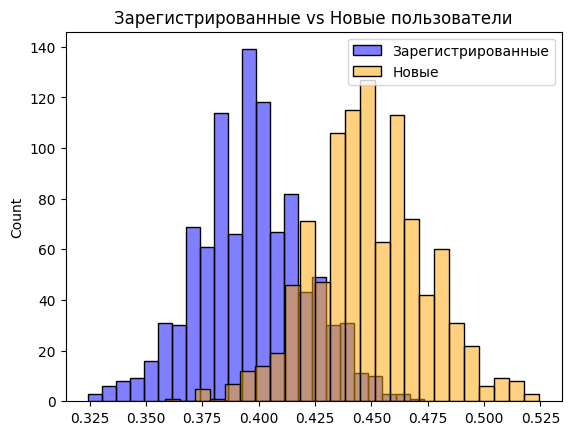

In [ ]:
auth_list = []
nauth_list = []

for _ in range(1000):
  df_auth_loc  = df_auth.sample(len(df_auth), replace=True)
  df_nauth_loc = df_n_auth.sample(len(df_auth), replace=True)

  m_auth = df_auth_loc['flag_success'].mean()
  m_nauth = df_nauth_loc['flag_success'].mean()

  auth_list.append(m_auth)
  nauth_list.append(m_nauth)

sns.histplot(auth_list, color = 'blue', alpha = .5, label = "Зарегистрированные")
sns.histplot(nauth_list, color = 'orange', alpha = .5, label = "Новые")
plt.title("Зарегистрированные vs Новые пользователи")
plt.legend()
plt.show()

Видим, что между двумя сегментами существует значимая разница, не только с точки зрения воздействия В, но и с точки зрения средней заинтересованности в данной скидке в целом.

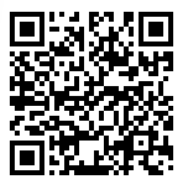